# Gunshot Detection — Full Pipeline, Corrected, Start to End

Complete rebuild of your dataset-audit + training + evaluation + inference pipeline in one
notebook. Nothing is left as "apply the diff to your old notebook" — every cell needed to go
from raw datasets to a trained, evaluated, inference-ready model is here.

**What's fixed vs. your original, and why (full detail in the corresponding sections below):**

| # | Problem in the original | Fix in this notebook |
|---|---|---|
| 1 | Feature extraction silently reverted to 128-bin log-mel + per-sample z-score normalization, which both breaks the required PCEN contract and destroys amplitude/distance cues | Section 6: canonical PCEN function (64 mel, exact company constants, no normalization), used identically everywhere in this notebook |
| 2 | Positive and negative classes came from almost entirely disjoint dataset sources (all gunfire datasets = positive, DEMAND/ESC-50/UrbanSound-non-gun = negative uncapped) — model could learn "which dataset" instead of "is this a gunshot" | Section 5: per-source negative caps, so no one source dominates and the model can't shortcut on source fingerprint |
| 3 | `FocalLoss` was defined but never used in the actual training loop | Section 10: FocalLoss is the loss actually used |
| 4 | Plain `train_test_split(stratify=label)`, no grouping — same-source-recording leakage across splits inflated validation metrics | Section 7: `StratifiedGroupKFold` using a `group_id` built per source dataset |
| 5 | `device` vs `DEVICE` naming inconsistency — relied on a stale variable from elsewhere in the notebook | Single `DEVICE` constant defined once (Section 1), used everywhere |
| 6 | Inference preprocessing (Notebook 12) was a separately-written function that drifted from training preprocessing | Section 13 reuses the exact Section 6 `extract_feature()` — impossible for them to diverge |
| 7 | No visibility into *where* errors were coming from | Section 12 adds a per-source-dataset accuracy breakdown next to the confusion matrix |

**One open item, unchanged from before:** this is a 2-class (Negative/Gunshot) model. The
company's Android app / `v7d12-pcen_runtime_config.json` contract expects a 12-class output
(`[1,12]`, with `gun_shot` at index 6, plus `impulse_pack`/`User_handling` hard-negative
classes) so it can plug into the existing thresholds and hysteresis logic. If this binary model
is meant to replace that model in production, it needs the output head changed and the Android
side updated to match — I can build that 12-class version instead if that's actually the target;
say the word and I'll adapt this same notebook.


## Section 1 — Setup

In [13]:
!pip -q install librosa soundfile audioread tqdm


In [14]:
import os, glob, json, random, warnings
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler

warnings.filterwarnings("ignore")


In [15]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Single device constant used everywhere in this notebook — fixes the device/DEVICE
# inconsistency that broke your original training loop on a clean kernel restart.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

MASTER_SAVE_DIR = "/kaggle/working/master_dataset"
os.makedirs(MASTER_SAVE_DIR, exist_ok=True)


Device: cuda


## Section 2 — Dataset paths & verification

In [16]:
DATASETS = {
    "Custom":       "/kaggle/input/datasets/shagnikguha/gunshot-detection-dataset-custom",
    "GunFire":      "/kaggle/input/datasets/endofnight17j03/gunfire-dataset",
    "GunshotAudio": "/kaggle/input/datasets/emrahaydemr/gunshot-audio-dataset",
    "ShotGraphNet": "/kaggle/input/datasets/manyevi/gunshot-audio-dataset",
    "Firearms58":   "/kaggle/input/datasets/zackyzac/firearms-audio-dataset-58-gun-types",
    "ESC50":        "/kaggle/input/datasets/niranjankn/esc50",
    "UrbanSound8K": "/kaggle/input/datasets/chrisfilo/urbansound8k",
    "DEMAND":       "/kaggle/input/datasets/chrisfilo/demand",
}

for name, path in DATASETS.items():
    print(("OK      " if os.path.exists(path) else "MISSING "), name, path)


OK       Custom /kaggle/input/datasets/shagnikguha/gunshot-detection-dataset-custom
OK       GunFire /kaggle/input/datasets/endofnight17j03/gunfire-dataset
OK       GunshotAudio /kaggle/input/datasets/emrahaydemr/gunshot-audio-dataset
OK       ShotGraphNet /kaggle/input/datasets/manyevi/gunshot-audio-dataset
OK       Firearms58 /kaggle/input/datasets/zackyzac/firearms-audio-dataset-58-gun-types
OK       ESC50 /kaggle/input/datasets/niranjankn/esc50
OK       UrbanSound8K /kaggle/input/datasets/chrisfilo/urbansound8k
OK       DEMAND /kaggle/input/datasets/chrisfilo/demand


In [17]:
AUDIO_EXTENSIONS = [".wav", ".mp3", ".flac", ".ogg", ".aac", ".m4a"]

def find_audio_files(folder):
    files = []
    for ext in AUDIO_EXTENSIONS:
        files.extend(glob.glob(os.path.join(folder, "**", f"*{ext}"), recursive=True))
    return sorted(files)

audio_summary = []
for name, path in DATASETS.items():
    files = find_audio_files(path)
    audio_summary.append([name, len(files)])
audio_summary = pd.DataFrame(audio_summary, columns=["Dataset", "Audio Files"])
display(audio_summary)


,Dataset,Audio Files
0,Custom,11731
1,GunFire,2148
2,GunshotAudio,851
3,ShotGraphNet,8877
4,Firearms58,1450
5,ESC50,2000
6,UrbanSound8K,8732
7,DEMAND,560


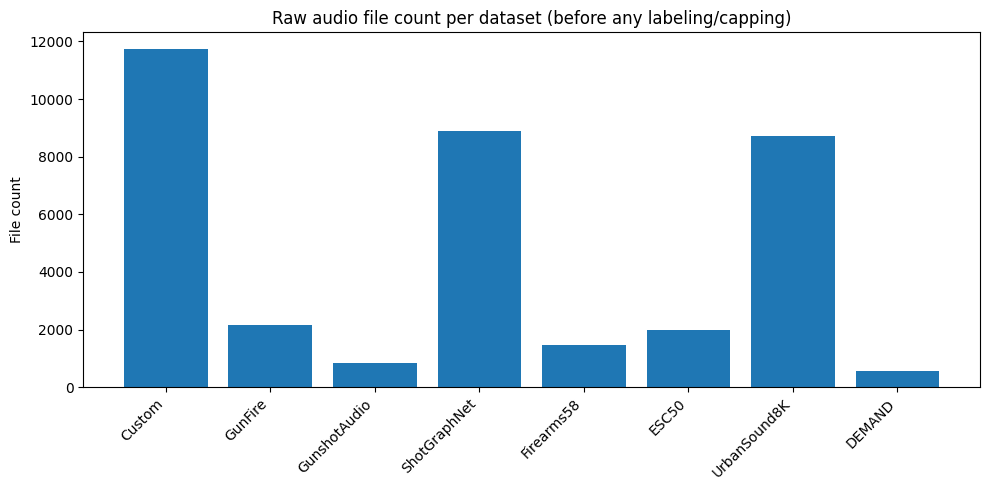

In [18]:
plt.figure(figsize=(10, 5))
plt.bar(audio_summary["Dataset"], audio_summary["Audio Files"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("File count")
plt.title("Raw audio file count per dataset (before any labeling/capping)")
plt.tight_layout()
plt.show()


## Section 3 — Audio metadata audit (sample rate, duration, channels, corrupted files)

Same audit your original Notebook 1 did — worth keeping, since sample-rate/duration outliers
and corrupted files are a common silent cause of degraded training data.

In [19]:
def probe_audio(path):
    try:
        info = sf.info(path) if 'sf' in dir() else None
    except Exception:
        info = None
    try:
        audio, sr = librosa.load(path, sr=None, mono=False)
        duration = audio.shape[-1] / sr
        channels = 1 if audio.ndim == 1 else audio.shape[0]
        return {"filepath": path, "sample_rate": sr, "duration": duration, "channels": channels, "ok": True}
    except Exception as e:
        return {"filepath": path, "sample_rate": np.nan, "duration": np.nan, "channels": np.nan, "ok": False}


all_files = []
for name, path in DATASETS.items():
    for f in find_audio_files(path):
        all_files.append((name, f))
print("Total files to audit:", len(all_files))


Total files to audit: 36349


In [20]:
# NOTE: auditing every single file (including all of DEMAND) can be slow on the full corpus.
# Sample a subset per dataset for the audit if you have tens of thousands of files — the goal
# here is catching systemic issues (wrong sample rate, corrupted files), not a 100% file check.
AUDIT_SAMPLE_PER_DATASET = 800

audit_rows = []
for name, path in DATASETS.items():
    files = find_audio_files(path)
    if len(files) > AUDIT_SAMPLE_PER_DATASET:
        files = random.sample(files, AUDIT_SAMPLE_PER_DATASET)
    for f in tqdm(files, desc=name):
        row = probe_audio(f)
        row["dataset"] = name
        audit_rows.append(row)

audit_df = pd.DataFrame(audit_rows)
print("Corrupted / unreadable files found:", (~audit_df["ok"]).sum())
audit_df[~audit_df["ok"]].head(20)


Custom:   0%|          | 0/800 [00:00<?, ?it/s]

GunFire:   0%|          | 0/800 [00:00<?, ?it/s]

GunshotAudio:   0%|          | 0/800 [00:00<?, ?it/s]

ShotGraphNet:   0%|          | 0/800 [00:00<?, ?it/s]

Firearms58:   0%|          | 0/800 [00:00<?, ?it/s]

ESC50:   0%|          | 0/800 [00:00<?, ?it/s]

UrbanSound8K:   0%|          | 0/800 [00:00<?, ?it/s]

DEMAND:   0%|          | 0/560 [00:00<?, ?it/s]

Corrupted / unreadable files found: 0


,filepath,sample_rate,duration,channels,ok,dataset


In [21]:
print("Sample rate distribution:")
print(audit_df["sample_rate"].value_counts())

print("\nDuration stats:")
print(audit_df["duration"].describe())

print("\nChannel distribution:")
print(audit_df["channels"].value_counts())


Sample rate distribution:
sample_rate
44100     3943
48000     1431
16000      504
96000      253
24000       11
11025        7
22050        6
8000         3
192000       2
Name: count, dtype: int64

Duration stats:
count    6160.000000
mean       30.081888
std        85.596876
min         0.050000
25%         2.000000
50%         3.750000
75%         5.000000
max       360.000000
Name: duration, dtype: float64

Channel distribution:
channels
1    3731
2    2429
Name: count, dtype: int64


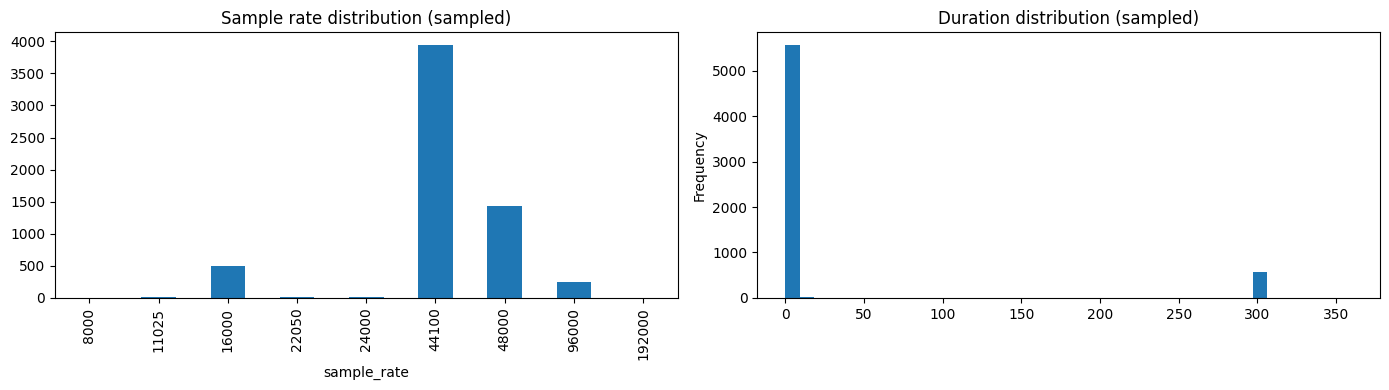

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
audit_df["sample_rate"].value_counts().sort_index().plot(kind="bar", ax=axes[0])
axes[0].set_title("Sample rate distribution (sampled)")
audit_df["duration"].dropna().plot(kind="hist", bins=40, ax=axes[1])
axes[1].set_title("Duration distribution (sampled)")
plt.tight_layout()
plt.show()


## Section 4 — Per-dataset label mapping

Each source is mapped to a binary `gun_shot` (1) / `not gun_shot` (0) label:

| Dataset | Mapping | Group key (leakage prevention) |
|---|---|---|
| GunFire, GunshotAudio, ShotGraphNet, Firearms58 | all files -> 1 | filename stem — **verify these aren't chunked from longer source recordings** (see ASSUMPTION comment below) |
| Custom | uses its own `labels.csv` `label` column directly | filename |
| UrbanSound8K | its own `gun_shot` class -> 1, everything else -> 0 | `fsID` (original Freesound recording id — several slice files share one fsID) |
| ESC-50 | no `gun_shot` category exists in ESC-50 (confirmed) -> always 0, pure negative pool | filename |
| DEMAND | ambient noise recordings -> 0, pure negative pool | parent folder (each folder = one long recording split into channel files) |


In [23]:
master_data = []

def add_record(filepath, label, source, group_id):
    master_data.append({
        "filepath": filepath, "label": int(label), "source": source,
        "group_id": f"{source}__{group_id}",
    })

for ds_name in ["GunFire", "GunshotAudio", "ShotGraphNet", "Firearms58"]:
    files = find_audio_files(DATASETS[ds_name])
    for fp in files:
        # ASSUMPTION: filename stem uniquely identifies the source recording. If any of these
        # datasets chop one recording into multiple numbered clips sharing a prefix
        # (e.g. "AK47_001.wav", "AK47_002.wav"), change group_id to that shared prefix instead.
        add_record(fp, 1, ds_name, os.path.splitext(os.path.basename(fp))[0])
    print(ds_name, ":", len(files))


GunFire : 2148
GunshotAudio : 851
ShotGraphNet : 8877
Firearms58 : 1450


In [24]:
custom_audio = os.path.join(DATASETS["Custom"], "CombinedAudio")
custom_csv = os.path.join(custom_audio, "labels.csv")
custom_df = pd.read_csv(custom_csv)
custom_df["filepath"] = custom_df["file_name"].apply(lambda x: os.path.join(custom_audio, x))
custom_df["source"] = "Custom"
custom_df["group_id"] = "Custom__" + custom_df["file_name"].astype(str)
custom_df = custom_df[["filepath", "label", "source", "group_id"]]
print(custom_df.shape)
print(custom_df["label"].value_counts())


(11731, 4)
label
0    8732
1    2999
Name: count, dtype: int64


In [25]:
urban_root = DATASETS["UrbanSound8K"]
urban_df = pd.read_csv(os.path.join(urban_root, "UrbanSound8K.csv"))
urban_df["filepath"] = urban_df.apply(
    lambda r: os.path.join(urban_root, f"fold{r['fold']}", r["slice_file_name"]), axis=1
)
urban_df["label"] = urban_df["class"].str.lower().eq("gun_shot").astype(int)
urban_df["source"] = "UrbanSound8K"
urban_df["group_id"] = "UrbanSound8K__" + urban_df["fsID"].astype(str)
urban_df = urban_df[["filepath", "label", "source", "group_id"]]
print(urban_df.shape)
print(urban_df["label"].value_counts())


(8732, 4)
label
0    8358
1     374
Name: count, dtype: int64


In [26]:
esc_audio = os.path.join(DATASETS["ESC50"], "ESC-50-master", "audio")
esc_meta  = os.path.join(DATASETS["ESC50"], "ESC-50-master", "meta", "esc50.csv")
esc_df = pd.read_csv(esc_meta)
esc_df["filepath"] = esc_df["filename"].apply(lambda x: os.path.join(esc_audio, x))
esc_df["label"] = 0  # confirmed: ESC-50 has no gun_shot category
esc_df["source"] = "ESC50"
esc_df["group_id"] = "ESC50__" + esc_df["filename"].astype(str)
esc_df = esc_df[["filepath", "label", "source", "group_id"]]
print(esc_df.shape)


(2000, 4)


In [27]:
demand_files = find_audio_files(DATASETS["DEMAND"])
demand_df = pd.DataFrame({
    "filepath": demand_files,
    "label": 0,
    "source": "DEMAND",
    "group_id": ["DEMAND__" + os.path.basename(os.path.dirname(f)) for f in demand_files],
})
print(demand_df.shape)


(560, 4)


## Section 5 — Combine + balance dataset sources

**Why this matters:** if every DEMAND/ESC-50/UrbanSound-non-gun file is used uncapped, the
negative class ends up 10-20x the size of the positive class *and* comes from almost entirely
different dataset sources than the positives. That lets the model learn "which dataset is
this" instead of "is this a gunshot" — good validation numbers, bad real-world / confusion-
matrix behavior. Capping each negative source keeps the negative class both closer in size to
the positive class and genuinely diverse across sources.

In [28]:
positive_df = pd.DataFrame(master_data)  # GunFire + GunshotAudio + ShotGraphNet + Firearms58
positive_df = pd.concat([positive_df, custom_df[custom_df.label == 1]], ignore_index=True)
positive_df = pd.concat([positive_df, urban_df[urban_df.label == 1]], ignore_index=True)

n_positive = len(positive_df)
print("Total positive (gun_shot) examples:", n_positive)

# Tune this after seeing n_positive above — a reasonable starting point is roughly 1x-2x total
# positives PER negative source, so no single source dominates.
NEG_PER_SOURCE_CAP = max(n_positive, 500)

neg_sources = {
    "Custom_neg":       custom_df[custom_df.label == 0],
    "UrbanSound8K_neg": urban_df[urban_df.label == 0],
    "ESC50":            esc_df,
    "DEMAND":           demand_df,
}

capped_negatives = []
for name, df_neg in neg_sources.items():
    available = len(df_neg)
    if available > NEG_PER_SOURCE_CAP:
        df_neg = df_neg.sample(NEG_PER_SOURCE_CAP, random_state=SEED)
    capped_negatives.append(df_neg)
    print(f"{name}: {len(df_neg)} negatives used (of {available} available)")

negative_df = pd.concat(capped_negatives, ignore_index=True)

master_df = pd.concat([positive_df, negative_df], ignore_index=True)
master_df = master_df.drop_duplicates(subset=["filepath"]).reset_index(drop=True)

print("\nFinal combined dataset:")
print(master_df["label"].value_counts())
print("Negative:Positive ratio ~=", (master_df.label == 0).sum() / max(1, (master_df.label == 1).sum()))


Total positive (gun_shot) examples: 16699
Custom_neg: 8732 negatives used (of 8732 available)
UrbanSound8K_neg: 8358 negatives used (of 8358 available)
ESC50: 2000 negatives used (of 2000 available)
DEMAND: 560 negatives used (of 560 available)

Final combined dataset:
label
0    19650
1    16699
Name: count, dtype: int64
Negative:Positive ratio ~= 1.176717168692736


In [29]:
master_df["exists"] = master_df["filepath"].apply(os.path.exists)
print(master_df["exists"].value_counts())
master_df = master_df[master_df["exists"]].drop(columns=["exists"]).reset_index(drop=True)

master_df.to_csv(os.path.join(MASTER_SAVE_DIR, "master_dataset.csv"), index=False)
master_df.head()


exists
True    36349
Name: count, dtype: int64


,filepath,label,source,group_id
0,/kaggle/input/datasets/endofnight17j03/gunfire...,1,GunFire,GunFire__03fc4685-909e-42c5-aff0-f519f1d14b12_...
1,/kaggle/input/datasets/endofnight17j03/gunfire...,1,GunFire,GunFire__03fc4685-909e-42c5-aff0-f519f1d14b12_...
2,/kaggle/input/datasets/endofnight17j03/gunfire...,1,GunFire,GunFire__03fc4685-909e-42c5-aff0-f519f1d14b12_...
3,/kaggle/input/datasets/endofnight17j03/gunfire...,1,GunFire,GunFire__03fc4685-909e-42c5-aff0-f519f1d14b12_...
4,/kaggle/input/datasets/endofnight17j03/gunfire...,1,GunFire,GunFire__03fc4685-909e-42c5-aff0-f519f1d14b12_...


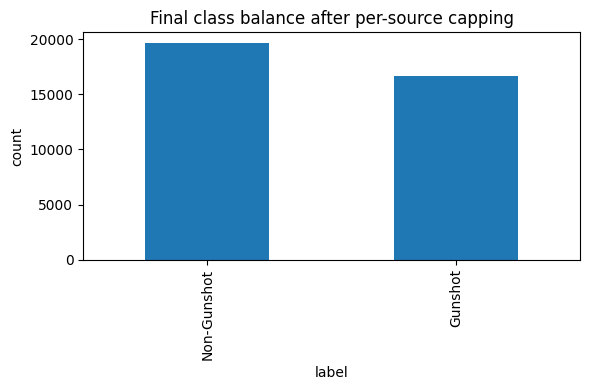

source        label
Custom        0        8732
              1        2999
DEMAND        0         560
ESC50         0        2000
Firearms58    1        1450
GunFire       1        2148
GunshotAudio  1         851
ShotGraphNet  1        8877
UrbanSound8K  0        8358
              1         374
dtype: int64


In [30]:
plt.figure(figsize=(6, 4))
master_df["label"].value_counts().rename({0: "Non-Gunshot", 1: "Gunshot"}).plot(kind="bar")
plt.title("Final class balance after per-source capping")
plt.ylabel("count")
plt.tight_layout()
plt.show()

print(master_df.groupby(["source", "label"]).size())


## Section 6 — Canonical PCEN feature extraction

**This is the single most important fix.** The original notebook's final training pipeline
used 128-bin log-mel spectrograms with per-sample z-score normalization — this both breaks the
company's required PCEN contract and, more importantly for accuracy, the z-score step erases
the amplitude/distance information that separates a loud close gunshot, a quiet distant one,
and background noise.

This function reproduces the exact contract instead: STFT power (n_fft=2048, hop=512) -> 64-band
mel using the **provided `mel-filterbank-2048.txt`** (not librosa's auto-generated filters, so
training sees the same mel matrix the Android app will use) -> manual PCEN recurrence with the
exact constants (`time_constant=0.06, gain=0.98, bias=2.0, power=0.5, eps=1e-6`) -> **no
normalization of any kind**. Output is `[125, 64, 1]`.

This exact function is reused for training, validation, evaluation, and inference later — there
is only one feature-extraction code path in this whole notebook.

In [31]:
SAMPLE_RATE, N_FFT, HOP_LENGTH, N_MELS, EXPECTED_FRAMES = 16000, 2048, 512, 64, 125
BLOCK_SAMPLES = 64000  # 4.0 seconds at 16 kHz
PCEN_TIME_CONSTANT, PCEN_GAIN, PCEN_BIAS, PCEN_POWER, PCEN_EPS = 0.06, 0.98, 2.0, 0.5, 1e-6

MEL_FB_PATH = "/kaggle/input/datasets/vaibhavchaudhary37/newly-gun/mel-filterbank-2048.txt"
mel_fb = np.loadtxt(MEL_FB_PATH, delimiter=",")
if mel_fb.shape == (N_MELS, N_FFT // 2 + 1):
    mel_fb = mel_fb.T
assert mel_fb.shape == (N_FFT // 2 + 1, N_MELS), f"unexpected mel filterbank shape {mel_fb.shape}"
print("mel filterbank shape:", mel_fb.shape)

def load_fixed_length_audio(path, target_len=BLOCK_SAMPLES, sr=SAMPLE_RATE):
    audio, _ = librosa.load(path, sr=sr, mono=True)
    if len(audio) < target_len:
        audio = np.pad(audio, (0, target_len - len(audio)))
    else:
        audio = audio[:target_len]
    return audio  # no peak/RMS normalization — preserves amplitude/distance cues


def pcen(mel_spec, time_constant=PCEN_TIME_CONSTANT, gain=PCEN_GAIN, bias=PCEN_BIAS,
         power=PCEN_POWER, eps=PCEN_EPS, hop=HOP_LENGTH, sr=SAMPLE_RATE):
    alpha = np.exp(-(hop / sr) / time_constant)
    M = np.zeros_like(mel_spec)
    M[0] = mel_spec[0]
    for t in range(1, mel_spec.shape[0]):
        M[t] = alpha * M[t - 1] + (1 - alpha) * mel_spec[t]
    return (mel_spec / (eps + M) ** gain + bias) ** power - bias ** power


def extract_feature(path):
    """Canonical PCEN feature extractor — the ONLY one used anywhere in this notebook."""
    y = load_fixed_length_audio(path)
    S = librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH, window="hann", center=True)
    power_spec = (np.abs(S) ** 2).T
    mel = np.maximum(power_spec @ mel_fb, 1e-10)
    feat = pcen(mel)
    if feat.shape[0] < EXPECTED_FRAMES:
        feat = np.pad(feat, ((0, EXPECTED_FRAMES - feat.shape[0]), (0, 0)))
    else:
        feat = feat[:EXPECTED_FRAMES]
    return feat.astype(np.float32)[..., np.newaxis]  # [125, 64, 1]


mel filterbank shape: (1025, 64)


gun_shot (125, 64, 1) min: 4.3492543e-11 max: 0.7046759


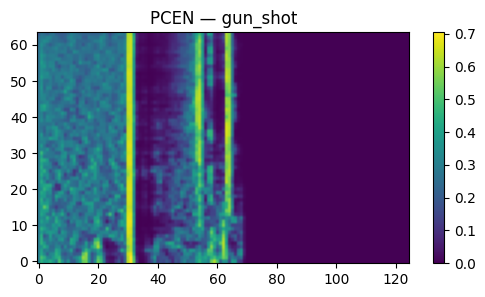

negative (125, 64, 1) min: 0.08127851 max: 0.4925207


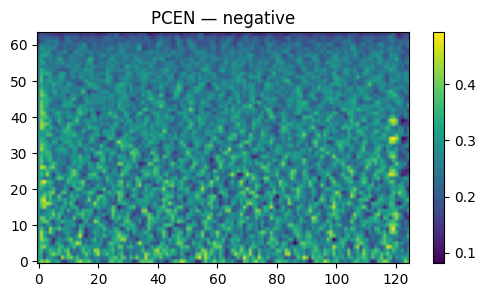

In [32]:
# Spot check — visually compare a gunshot vs a negative
for cls_val, name in [(1, "gun_shot"), (0, "negative")]:
    sub = master_df[master_df.label == cls_val]
    fp = sub.sample(1, random_state=SEED).iloc[0].filepath
    feat = extract_feature(fp)
    print(name, feat.shape, "min:", feat.min(), "max:", feat.max())
    plt.figure(figsize=(6, 3))
    plt.imshow(feat[..., 0].T, origin="lower", aspect="auto")
    plt.title(f"PCEN — {name}")
    plt.colorbar()
    plt.show()


In [33]:
# Check a batch of files for load failures before committing to a full training run
bad_files = []
for fp in tqdm(master_df["filepath"].sample(min(500, len(master_df)), random_state=SEED)):
    try:
        _ = extract_feature(fp)
    except Exception as e:
        bad_files.append((fp, str(e)))
print("Failures in sampled check:", len(bad_files))
bad_files[:10]


  0%|          | 0/500 [00:00<?, ?it/s]

Failures in sampled check: 0


[]

## Section 7 — Group-aware stratified train/val/test split

Uses `StratifiedGroupKFold` with the `group_id` column built in Section 4, so clips from the
same source recording never land in more than one split. This closes the leakage path that was
inflating validation/test metrics relative to real generalization in the original notebook's
plain `train_test_split(stratify=label)`.

In [34]:
def stratified_group_split(df, n_folds):
    sgkf = StratifiedGroupKFold(n_splits=n_folds, shuffle=True, random_state=SEED)
    keep_idx, holdout_idx = next(sgkf.split(df, df["label"], groups=df["group_id"]))
    return df.iloc[keep_idx].reset_index(drop=True), df.iloc[holdout_idx].reset_index(drop=True)

train_df, holdout_df = stratified_group_split(master_df, n_folds=5)   # ~80/20
val_df, test_df       = stratified_group_split(holdout_df, n_folds=2)  # ~50/50 of the 20%

print("train:", len(train_df), " val:", len(val_df), " test:", len(test_df))
print("\ntrain balance:\n", train_df["label"].value_counts())
print("\nval balance:\n", val_df["label"].value_counts())
print("\ntest balance:\n", test_df["label"].value_counts())

assert set(train_df.group_id) & set(val_df.group_id) == set()
assert set(train_df.group_id) & set(test_df.group_id) == set()
assert set(val_df.group_id) & set(test_df.group_id) == set()
print("\nNo group leakage across splits — confirmed.")

train_df.to_csv(os.path.join(MASTER_SAVE_DIR, "train.csv"), index=False)
val_df.to_csv(os.path.join(MASTER_SAVE_DIR, "val.csv"), index=False)
test_df.to_csv(os.path.join(MASTER_SAVE_DIR, "test.csv"), index=False)


train: 29091  val: 3655  test: 3603

train balance:
 label
0    15753
1    13338
Name: count, dtype: int64

val balance:
 label
0    1966
1    1689
Name: count, dtype: int64

test balance:
 label
0    1931
1    1672
Name: count, dtype: int64

No group leakage across splits — confirmed.


## Section 8 — PyTorch Dataset / DataLoader

In [35]:
print(train_df["filepath"].iloc[0])
print(os.path.exists(train_df["filepath"].iloc[0]))

/kaggle/input/datasets/endofnight17j03/gunfire-dataset/edge-collected-gunshot-audio/edge-collected-gunshot-audio/38s_andws_dot38_caliber/03fc4685-909e-42c5-aff0-f519f1d14b12_chan0_v0.wav
True


In [36]:
for p in train_df["filepath"].head(10):
    print(p, "->", os.path.exists(p))

/kaggle/input/datasets/endofnight17j03/gunfire-dataset/edge-collected-gunshot-audio/edge-collected-gunshot-audio/38s_andws_dot38_caliber/03fc4685-909e-42c5-aff0-f519f1d14b12_chan0_v0.wav -> True
/kaggle/input/datasets/endofnight17j03/gunfire-dataset/edge-collected-gunshot-audio/edge-collected-gunshot-audio/38s_andws_dot38_caliber/03fc4685-909e-42c5-aff0-f519f1d14b12_chan1_v0.wav -> True
/kaggle/input/datasets/endofnight17j03/gunfire-dataset/edge-collected-gunshot-audio/edge-collected-gunshot-audio/38s_andws_dot38_caliber/03fc4685-909e-42c5-aff0-f519f1d14b12_chan2_v0.wav -> True
/kaggle/input/datasets/endofnight17j03/gunfire-dataset/edge-collected-gunshot-audio/edge-collected-gunshot-audio/38s_andws_dot38_caliber/03fc4685-909e-42c5-aff0-f519f1d14b12_chan3_v0.wav -> True
/kaggle/input/datasets/endofnight17j03/gunfire-dataset/edge-collected-gunshot-audio/edge-collected-gunshot-audio/38s_andws_dot38_caliber/03fc4685-909e-42c5-aff0-f519f1d14b12_chan5_v0.wav -> True
/kaggle/input/datasets/en

In [37]:
class GunshotDataset(Dataset):
    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        feat = extract_feature(row["filepath"])  # [125, 64, 1]

        feat_t = torch.tensor(
            feat, dtype=torch.float32
        ).permute(2, 0, 1)  # [1, 125, 64]

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return feat_t, label


# IMPORTANT for Kaggle
BATCH_SIZE = 64
NUM_WORKERS = 0

train_dataset = GunshotDataset(train_df)
val_dataset = GunshotDataset(val_df)
test_dataset = GunshotDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

# Test one batch
x, y = next(iter(train_loader))

print("X shape:", x.shape)
print("Y shape:", y.shape)

X shape: torch.Size([64, 1, 125, 64])
Y shape: torch.Size([64])


## Section 9 — Model: CBAM-CNN

Same architecture as your original — channel + spatial attention (CBAM) after each conv block.
It's shape-agnostic via `AdaptiveAvgPool2d`, so no architecture change was needed once the
feature extractor was fixed to produce the correct `[1, 125, 64]` tensor.

In [38]:
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(channels // reduction, channels, 1, bias=False),
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.fc(self.avg_pool(x))
        mx = self.fc(self.max_pool(x))
        return x * self.sigmoid(avg + mx)


class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)
        attn = self.sigmoid(self.conv(torch.cat([avg, mx], dim=1)))
        return x * attn


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel = ChannelAttention(channels)
        self.spatial = SpatialAttention()

    def forward(self, x):
        x = self.channel(x)
        x = self.spatial(x)
        return x


class GunshotCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2), CBAM(32),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2), CBAM(64),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2), CBAM(128),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(128, 2)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        return self.fc(x)


model = GunshotCNN().to(DEVICE)
print(sum(p.numel() for p in model.parameters()), "parameters")
out = model(x.to(DEVICE))
print(out.shape)  # expect [batch, 2]


96363 parameters
torch.Size([64, 2])


## Section 10 — Loss, optimizer, scheduler

Uses `FocalLoss` combined with balanced class weights. In the original notebook, `FocalLoss`
was defined but the actual training loop used plain `nn.CrossEntropyLoss(weight=weights)`
instead — losing the mechanism that down-weights easy majority-class examples. This version
actually uses it.

In [39]:
classes = np.array([0, 1])
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=train_df["label"])
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print("class weights:", class_weights)


class FocalLoss(nn.Module):
    def __init__(self, alpha_weights=None, gamma=2.0):
        super().__init__()
        self.alpha_weights = alpha_weights
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce = F.cross_entropy(inputs, targets, weight=self.alpha_weights, reduction="none")
        pt = torch.exp(-ce)
        loss = (1 - pt) ** self.gamma * ce
        return loss.mean()


criterion = FocalLoss(alpha_weights=class_weights, gamma=2.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)
scaler = GradScaler(enabled=(DEVICE.type == "cuda"))


class weights: tensor([0.9233, 1.0905], device='cuda:0')


## Section 11 — Training loop

In [40]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("❌ GPU is NOT available")

PyTorch version: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA version: 12.8


In [41]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [42]:
model = model.to(device)

In [43]:
# def train_one_epoch():
#     model.train()
#     running_loss = 0.0
#     for images, labels in tqdm(train_loader):
#         images = images.to(DEVICE, non_blocking=True) # i change
#         labels = labels.to(DEVICE, non_blocking=True) # i change
#         optimizer.zero_grad(set_to_none=True) # i change
#         with autocast(enabled=(DEVICE.type == "cuda")):
#             outputs = model(images)
#             loss = criterion(outputs, labels)
#         scaler.scale(loss).backward()
#         scaler.step(optimizer)
#         scaler.update()
#         running_loss += loss.item()
#     return running_loss / len(train_loader)


# @torch.no_grad()
# def validate():
#     model.eval()
#     preds, labels_all, losses = [], [], []
#     for images, labels in val_loader:
#         images = images.to(DEVICE, non_blocking=True) # i change
#         labels = labels.to(DEVICE, non_blocking=True) # i change
#         outputs = model(images)
#         loss = criterion(outputs, labels)
#         losses.append(loss.item())
#         preds.extend(outputs.argmax(1).cpu().numpy())
#         labels_all.extend(labels.cpu().numpy())
#     return (np.mean(losses), accuracy_score(labels_all, preds),
#             precision_score(labels_all, preds), recall_score(labels_all, preds),
#             f1_score(labels_all, preds))
import numpy as np
import torch
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)


# ============================================================
# MOVE MODEL TO GPU
# ============================================================

model = model.to(DEVICE)

print("Model device:", next(model.parameters()).device)


# ============================================================
# MIXED PRECISION
# ============================================================

# Use AMP only when GPU is available
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=(DEVICE.type == "cuda")
)


# ============================================================
# TRAIN ONE EPOCH
# ============================================================

def train_one_epoch():

    model.train()

    running_loss = 0.0

    progress_bar = tqdm(
        train_loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress_bar:

        # Move data to GPU
        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        # Clear gradients
        optimizer.zero_grad(set_to_none=True)

        # Mixed precision on GPU
        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        # Backpropagation
        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        # Track loss
        running_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return running_loss / len(train_loader)


# ============================================================
# VALIDATION
# ============================================================

@torch.no_grad()
def validate():

    model.eval()

    preds = []
    labels_all = []
    losses = []

    progress_bar = tqdm(
        val_loader,
        desc="Validation",
        leave=False
    )

    for images, labels in progress_bar:

        # Move data to GPU
        images = images.to(
            DEVICE,
            non_blocking=True
        )

        labels = labels.to(
            DEVICE,
            non_blocking=True
        )

        # Forward pass
        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        losses.append(loss.item())

        # Predictions
        batch_preds = outputs.argmax(dim=1)

        # Move only predictions/labels back to CPU
        preds.extend(
            batch_preds.cpu().numpy()
        )

        labels_all.extend(
            labels.cpu().numpy()
        )

    # ========================================================
    # METRICS
    # ========================================================

    accuracy = accuracy_score(
        labels_all,
        preds
    )

    precision = precision_score(
        labels_all,
        preds,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        labels_all,
        preds,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        labels_all,
        preds,
        average="weighted",
        zero_division=0
    )

    val_loss = np.mean(losses)

    return (
        val_loss,
        accuracy,
        precision,
        recall,
        f1
    )

Using device: cuda
GPU: Tesla T4
CUDA: 12.8
Model device: cuda:0


In [44]:
# EPOCHS = 30
# best_f1 = 0.0
# history = {"train_loss": [], "val_loss": [], "accuracy": [], "precision": [], "recall": [], "f1": []}
# SAVE_PATH = "/kaggle/working/best_model_corrected.pth"

# for epoch in range(EPOCHS):
#     train_loss = train_one_epoch()
#     val_loss, acc, pre, rec, f1 = validate()
#     history["train_loss"].append(train_loss)
#     history["val_loss"].append(val_loss)
#     history["accuracy"].append(acc)
#     history["precision"].append(pre)
#     history["recall"].append(rec)
#     history["f1"].append(f1)
#     scheduler.step(f1)

#     print("=" * 60)
#     print(f"Epoch {epoch+1}/{EPOCHS}")
#     print(f"Train Loss : {train_loss:.4f}   Val Loss : {val_loss:.4f}")
#     print(f"Accuracy : {acc:.4f}  Precision : {pre:.4f}  Recall : {rec:.4f}  F1 : {f1:.4f}")

#     if f1 > best_f1:
#         best_f1 = f1
#         torch.save(model.state_dict(), SAVE_PATH)
#         print("Best model saved.")

# pd.DataFrame(history).to_csv("/kaggle/working/training_history_corrected.csv", index=False)
# ============================================================
# TRAINING
# ============================================================

EPOCHS = 30

best_f1 = 0.0

history = {
    "train_loss": [],
    "val_loss": [],
    "accuracy": [],
    "precision": [],
    "recall": [],
    "f1": []
}

SAVE_PATH = "/kaggle/working/best_model_corrected.pth"


for epoch in range(EPOCHS):

    print("=" * 70)
    print(f"Epoch {epoch + 1}/{EPOCHS}")

    # -------------------------
    # Training
    # -------------------------

    train_loss = train_one_epoch()

    # -------------------------
    # Validation
    # -------------------------

    val_loss, acc, pre, rec, f1 = validate()

    # -------------------------
    # Save history
    # -------------------------

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["accuracy"].append(acc)
    history["precision"].append(pre)
    history["recall"].append(rec)
    history["f1"].append(f1)

    # -------------------------
    # Scheduler
    # -------------------------

    scheduler.step(f1)

    # -------------------------
    # Print results
    # -------------------------

    print(
        f"Train Loss : {train_loss:.4f}"
    )

    print(
        f"Val Loss   : {val_loss:.4f}"
    )

    print(
        f"Accuracy   : {acc:.4f}"
    )

    print(
        f"Precision  : {pre:.4f}"
    )

    print(
        f"Recall     : {rec:.4f}"
    )

    print(
        f"F1 Score   : {f1:.4f}"
    )

    # -------------------------
    # Save best model
    # -------------------------

    if f1 > best_f1:

        best_f1 = f1

        torch.save(
            model.state_dict(),
            SAVE_PATH
        )

        print(
            f"✓ Best model saved! F1 = {best_f1:.4f}"
        )

    print()

Epoch 1/30


Training:   0%|          | 0/454 [00:00<?, ?it/s]

Validation:   0%|          | 0/58 [00:00<?, ?it/s]

Train Loss : 0.0357
Val Loss   : 0.0303
Accuracy   : 0.9636
Precision  : 0.9641
Recall     : 0.9636
F1 Score   : 0.9636
✓ Best model saved! F1 = 0.9636

Epoch 2/30


Training:   0%|          | 0/454 [00:00<?, ?it/s]

Validation:   0%|          | 0/58 [00:00<?, ?it/s]

... (81 outputs left out)

Train Loss : 0.0032
Val Loss   : 0.0258
Accuracy   : 0.9770
Precision  : 0.9770
Recall     : 0.9770
F1 Score   : 0.9770

Epoch 30/30


Training:   0%|          | 0/454 [00:00<?, ?it/s]

Validation:   0%|          | 0/58 [00:00<?, ?it/s]

Train Loss : 0.0032
Val Loss   : 0.0266
Accuracy   : 0.9773
Precision  : 0.9773
Recall     : 0.9773
F1 Score   : 0.9773



In [46]:
# history_df = pd.DataFrame(history)
# fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# axes[0].plot(history_df["train_loss"], label="train")
# axes[0].plot(history_df["val_loss"], label="val")
# axes[0].set_title("Loss")
# axes[0].legend()
# axes[1].plot(history_df["accuracy"], label="accuracy")
# axes[1].plot(history_df["f1"], label="f1")
# axes[1].plot(history_df["recall"], label="recall")
# axes[1].set_title("Validation metrics")
# axes[1].legend()
# plt.tight_layout()
# plt.show()
# ============================================================
# SAVE TRAINING HISTORY
# ============================================================

history_df = pd.DataFrame(history)

history_path = (
    "/kaggle/working/"
    "training_history_corrected.csv"
)

history_df.to_csv(
    history_path,
    index=False
)

print("Training history saved to:")
print(history_path)

Training history saved to:
/kaggle/working/training_history_corrected.csv


## Section 12 — Test-set evaluation: metrics, confusion matrix, ROC, PR curve, per-source diagnostic

In [49]:
# model.load_state_dict(torch.load(SAVE_PATH, map_location=DEVICE))
# model.eval()

# all_labels, all_preds, all_probs = [], [], []
# with torch.no_grad():
#     for images, labels in test_loader:
#         images = images.to(DEVICE)
#         outputs = model(images)
#         probs = F.softmax(outputs, dim=1)
#         preds = torch.argmax(probs, dim=1)
#         all_labels.extend(labels.numpy())
#         all_preds.extend(preds.cpu().numpy())
#         all_probs.extend(probs[:, 1].cpu().numpy())

# all_sources = test_df["source"].tolist()  # test_loader is not shuffled, order matches test_df

# accuracy  = accuracy_score(all_labels, all_preds)
# precision = precision_score(all_labels, all_preds)
# recall    = recall_score(all_labels, all_preds)
# f1        = f1_score(all_labels, all_preds)
# roc_auc   = roc_auc_score(all_labels, all_probs)

# print(f"Accuracy  : {accuracy:.4f}")
# print(f"Precision : {precision:.4f}")
# print(f"Recall    : {recall:.4f}")
# print(f"F1 Score  : {f1:.4f}")
# print(f"ROC AUC   : {roc_auc:.4f}")
# print()
# print(classification_report(all_labels, all_preds, target_names=["Non-Gunshot", "Gunshot"]))
# ============================================================
# LOAD BEST MODEL
# ============================================================

model.load_state_dict(
    torch.load(
        SAVE_PATH,
        map_location=DEVICE
    )
)

model = model.to(DEVICE)
model.eval()


# ============================================================
# TEST / EVALUATION
# ============================================================

all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():

    for images, labels in tqdm(
        test_loader,
        desc="Testing"
    ):

        # Move images to GPU
        images = images.to(
            DEVICE,
            non_blocking=True
        )

        # Forward pass
        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):

            outputs = model(images)

            probs = F.softmax(
                outputs,
                dim=1
            )

        # Predicted class
        preds = torch.argmax(
            probs,
            dim=1
        )

        # Store results on CPU
        all_labels.extend(
            labels.numpy()
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

        # Probability of class 1 = Gunshot
        all_probs.extend(
            probs[:, 1].cpu().numpy()
        )


# ============================================================
# SOURCE INFORMATION
# ============================================================

# test_loader is not shuffled, therefore order matches test_df
all_sources = test_df["source"].tolist()


# ============================================================
# METRICS
# ============================================================

accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    zero_division=0
)

roc_auc = roc_auc_score(
    all_labels,
    all_probs
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 60)
print("TEST RESULTS")
print("=" * 60)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC AUC   : {roc_auc:.4f}")

print()
print("Classification Report")
print("=" * 60)

print(
    classification_report(
        all_labels,
        all_preds,
        target_names=[
            "Non-Gunshot",
            "Gunshot"
        ],
        zero_division=0
    )
)

Testing:   0%|          | 0/57 [00:00<?, ?it/s]

TEST RESULTS
Accuracy  : 0.9839
Precision : 0.9781
Recall    : 0.9874
F1 Score  : 0.9827
ROC AUC   : 0.9994

Classification Report
              precision    recall  f1-score   support

 Non-Gunshot       0.99      0.98      0.98      1931
     Gunshot       0.98      0.99      0.98      1672

    accuracy                           0.98      3603
   macro avg       0.98      0.98      0.98      3603
weighted avg       0.98      0.98      0.98      3603



Confusion Matrix:
[[1894   37]
 [  21 1651]]


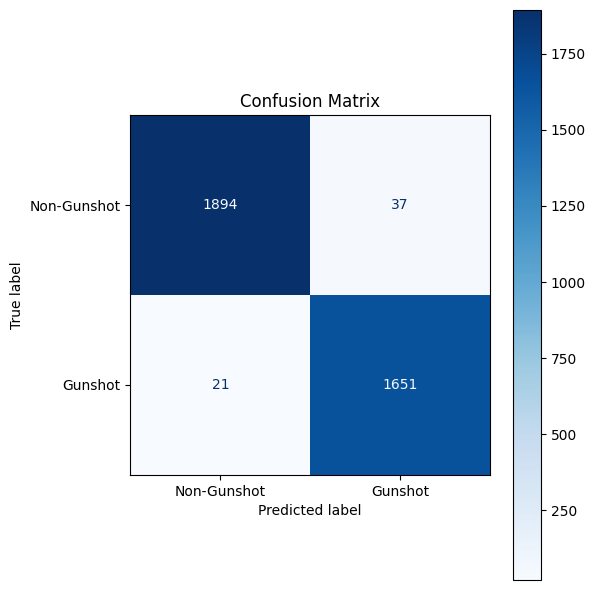


Saved to:
/kaggle/working/confusion_matrix_corrected.png


In [50]:
# cm = confusion_matrix(all_labels, all_preds)
# disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Gunshot", "Gunshot"])
# fig, ax = plt.subplots(figsize=(6, 6))
# disp.plot(ax=ax, cmap="Blues")
# plt.title("Confusion Matrix")
# plt.savefig("/kaggle/working/confusion_matrix_corrected.png", dpi=300, bbox_inches="tight")
# plt.show()
# ============================================================
# CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_preds
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Non-Gunshot",
        "Gunshot"
    ]
)

fig, ax = plt.subplots(
    figsize=(6, 6)
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title(
    "Confusion Matrix"
)

plt.tight_layout()

# Save
cm_path = (
    "/kaggle/working/"
    "confusion_matrix_corrected.png"
)

plt.savefig(
    cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved to:")
print(cm_path)

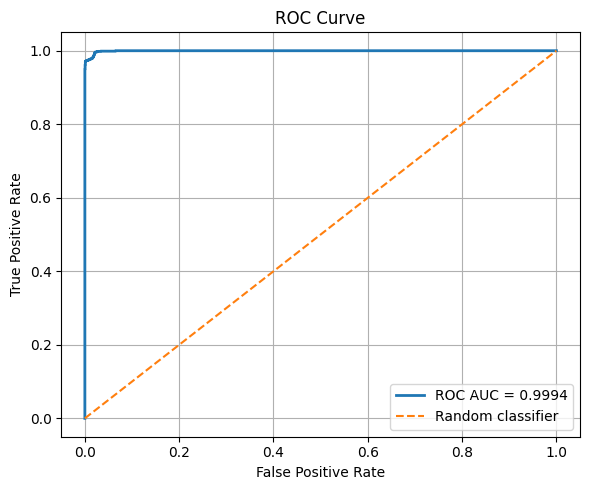

ROC curve saved to:
/kaggle/working/roc_curve_corrected.png
ROC AUC = 0.9994


In [51]:
# fpr, tpr, _ = roc_curve(all_labels, all_probs)
# plt.figure(figsize=(6, 5))
# plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.4f}")
# plt.plot([0, 1], [0, 1], "--")
# plt.xlabel("False Positive Rate")
# plt.ylabel("True Positive Rate")
# plt.title("ROC Curve")
# plt.legend()
# plt.grid(True)
# plt.savefig("/kaggle/working/roc_curve_corrected.png", dpi=300, bbox_inches="tight")
# plt.show()

# precision_curve, recall_curve, _ = precision_recall_curve(all_labels, all_probs)
# plt.figure(figsize=(6, 5))
# plt.plot(recall_curve, precision_curve)
# plt.xlabel("Recall")
# plt.ylabel("Precision")
# plt.title("Precision-Recall Curve")
# plt.grid(True)
# plt.savefig("/kaggle/working/pr_curve_corrected.png", dpi=300, bbox_inches="tight")
# plt.show()
# ============================================================
# ROC CURVE
# ============================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC
fpr, tpr, thresholds = roc_curve(
    all_labels,
    all_probs
)

# Calculate AUC
roc_auc = auc(
    fpr,
    tpr
)

# Plot
plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC AUC = {roc_auc:.4f}",
    linewidth=2
)

# Random classifier
plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)

plt.tight_layout()

# Save
roc_path = (
    "/kaggle/working/"
    "roc_curve_corrected.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC curve saved to:")
print(roc_path)

print(f"ROC AUC = {roc_auc:.4f}")

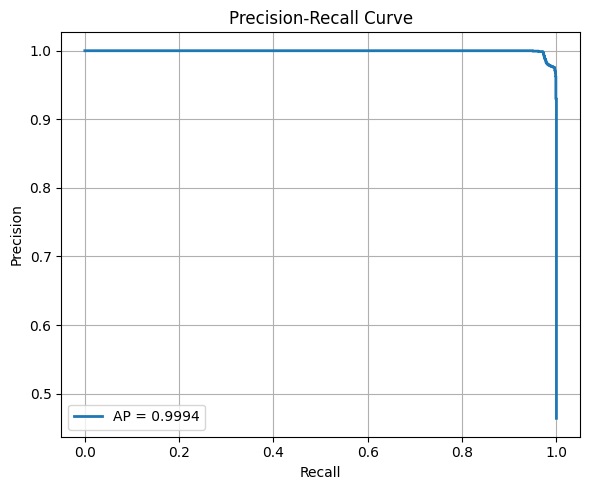

Precision-Recall curve saved to:
/kaggle/working/pr_curve_corrected.png
Average Precision = 0.9994


In [52]:
# ============================================================
# PRECISION-RECALL CURVE
# ============================================================

from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate Precision-Recall
precision_curve, recall_curve, thresholds_pr = precision_recall_curve(
    all_labels,
    all_probs
)

# Average Precision
average_precision = average_precision_score(
    all_labels,
    all_probs
)

# Plot
plt.figure(figsize=(6, 5))

plt.plot(
    recall_curve,
    precision_curve,
    linewidth=2,
    label=f"AP = {average_precision:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(True)

plt.tight_layout()

# Save
pr_path = (
    "/kaggle/working/"
    "pr_curve_corrected.png"
)

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Precision-Recall curve saved to:")
print(pr_path)

print(f"Average Precision = {average_precision:.4f}")

In [53]:
# # Diagnostic: accuracy broken down by source dataset. If errors cluster heavily in one or two
# # sources, that's a strong signal the model is still keying off dataset/recording fingerprints
# # rather than the actual acoustic signal, and that source needs more diversity/augmentation
# # rather than just more raw volume.
# diag_df = pd.DataFrame({"source": all_sources, "true": all_labels, "pred": all_preds})
# diag_df["correct"] = diag_df["true"] == diag_df["pred"]
# error_by_source = diag_df.groupby("source")["correct"].agg(["mean", "count"]).rename(
#     columns={"mean": "accuracy", "count": "n_samples"}
# ).sort_values("accuracy")
# print(error_by_source)
# ============================================================
# DIAGNOSTIC: PERFORMANCE BY SOURCE DATASET
# ============================================================

import pandas as pd

# Create diagnostic dataframe
diag_df = pd.DataFrame({
    "source": all_sources,
    "true": all_labels,
    "pred": all_preds
})

# Correct / incorrect prediction
diag_df["correct"] = (
    diag_df["true"] == diag_df["pred"]
)

# Error indicator
diag_df["error"] = (
    diag_df["true"] != diag_df["pred"]
)

# ============================================================
# ACCURACY BY SOURCE
# ============================================================

error_by_source = (
    diag_df
    .groupby("source")["correct"]
    .agg(
        accuracy="mean",
        n_samples="count"
    )
)

# Number of errors
error_by_source["n_errors"] = (
    diag_df
    .groupby("source")["error"]
    .sum()
)

# Convert accuracy to percentage
error_by_source["accuracy_percent"] = (
    error_by_source["accuracy"] * 100
)

# Sort from worst to best
error_by_source = error_by_source.sort_values(
    "accuracy"
)

print("=" * 70)
print("MODEL PERFORMANCE BY SOURCE DATASET")
print("=" * 70)

print(
    error_by_source[
        [
            "accuracy_percent",
            "n_samples",
            "n_errors"
        ]
    ].round(2)
)

MODEL PERFORMANCE BY SOURCE DATASET
              accuracy_percent  n_samples  n_errors
source                                             
Custom                   97.10       1171        34
UrbanSound8K             98.04        868        17
ESC50                    98.50        200         3
GunFire                  99.54        216         1
ShotGraphNet             99.66        883         3
DEMAND                  100.00         32         0
Firearms58              100.00        147         0
GunshotAudio            100.00         86         0


In [54]:
# ============================================================
# SOURCE DISTRIBUTION
# ============================================================

source_counts = (
    diag_df["source"]
    .value_counts()
    .rename("n_samples")
)

print("\nSource distribution:")
print(source_counts)


Source distribution:
source
Custom          1171
ShotGraphNet     883
UrbanSound8K     868
GunFire          216
ESC50            200
Firearms58       147
GunshotAudio      86
DEMAND            32
Name: n_samples, dtype: int64


In [55]:
# ============================================================
# SHOW MISCLASSIFIED SAMPLES BY SOURCE
# ============================================================

errors_only = diag_df[
    diag_df["correct"] == False
].copy()

print(
    errors_only.groupby("source")
    .size()
    .sort_values(ascending=False)
)

source
Custom          34
UrbanSound8K    17
ESC50            3
ShotGraphNet     3
GunFire          1
dtype: int64


In [56]:
# results = pd.DataFrame({
#     "Metric": ["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"],
#     "Value": [accuracy, precision, recall, f1, roc_auc],
# })
# results.to_csv("/kaggle/working/test_results_corrected.csv", index=False)
# results
# ============================================================
# SAVE FINAL TEST RESULTS
# ============================================================

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC",
        "Average_Precision"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        average_precision
    ]
})

# Save CSV
results_path = (
    "/kaggle/working/"
    "test_results_corrected.csv"
)

results.to_csv(
    results_path,
    index=False
)

# Display results
print("=" * 50)
print("FINAL TEST RESULTS")
print("=" * 50)

display(
    results.style.format({
        "Value": "{:.4f}"
    })
)

print("\nSaved to:")
print(results_path)

FINAL TEST RESULTS


,Metric,Value
0,Accuracy,0.9839
1,Precision,0.9781
2,Recall,0.9874
3,F1,0.9827
4,ROC_AUC,0.9994
5,Average_Precision,0.9994



Saved to:
/kaggle/working/test_results_corrected.csv


## Section 13 — Inference

Uses the exact same `extract_feature()` from Section 6 — no separately-written inference
preprocessing function to drift out of sync with training, which was one of the original bugs.

In [57]:
# CLASS_NAMES = {0: "Non-Gunshot", 1: "Gunshot"}

# def predict(audio_path, show_plot=False):
#     feat = extract_feature(audio_path)
#     feat_t = torch.tensor(feat).permute(2, 0, 1).unsqueeze(0).to(DEVICE)
#     with torch.no_grad():
#         probs = torch.softmax(model(feat_t), dim=1)
#         pred = torch.argmax(probs, dim=1).item()
#         confidence = probs[0][pred].item()
#     if show_plot:
#         plt.figure(figsize=(6, 3))
#         plt.imshow(feat[..., 0].T, origin="lower", aspect="auto")
#         plt.title(f"{CLASS_NAMES[pred]} ({confidence*100:.1f}%)")
#         plt.colorbar()
#         plt.show()
#     print(f"Prediction: {CLASS_NAMES[pred]}   Confidence: {confidence*100:.2f}%")
#     return pred, confidence


# def predict_folder(folder):
#     results = []
#     for file in os.listdir(folder):
#         if not file.lower().endswith(tuple(AUDIO_EXTENSIONS)):
#             continue
#         path = os.path.join(folder, file)
#         pred, conf = predict(path)
#         results.append([file, CLASS_NAMES[pred], conf])
#     results_df = pd.DataFrame(results, columns=["File", "Prediction", "Confidence"])
#     results_df.to_csv("/kaggle/working/inference_results_corrected.csv", index=False)
#     return results_df

# # Example:
# # predict("/kaggle/input/datasets/endofnight17j03/gunfire-dataset/.../some_file.wav", show_plot=True)
# # predict_folder("/kaggle/input/datasets/endofnight17j03/gunfire-dataset/.../glock_17_9mm_caliber")
# ============================================================
# INFERENCE / PREDICTION
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Class names
# ------------------------------------------------------------

CLASS_NAMES = {
    0: "Non-Gunshot",
    1: "Gunshot"
}


# ------------------------------------------------------------
# Load best trained model
# ------------------------------------------------------------

model.load_state_dict(
    torch.load(
        SAVE_PATH,
        map_location=DEVICE
    )
)

model = model.to(DEVICE)
model.eval()

print("Model loaded successfully.")
print("Device:", DEVICE)


# ============================================================
# SINGLE AUDIO PREDICTION
# ============================================================

def predict(audio_path, show_plot=False):

    # Check file
    if not os.path.isfile(audio_path):
        raise FileNotFoundError(
            f"Audio file not found:\n{audio_path}"
        )

    # Extract feature
    feat = extract_feature(audio_path)

    # Convert to tensor
    feat_t = torch.tensor(
        feat,
        dtype=torch.float32
    ).permute(2, 0, 1).unsqueeze(0)

    # Move to GPU/CPU
    feat_t = feat_t.to(
        DEVICE,
        non_blocking=True
    )

    # Prediction
    with torch.no_grad():

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):

            outputs = model(feat_t)

            probs = torch.softmax(
                outputs,
                dim=1
            )

        pred = torch.argmax(
            probs,
            dim=1
        ).item()

        confidence = probs[0, pred].item()

    # --------------------------------------------------------
    # Print result
    # --------------------------------------------------------

    print("=" * 60)
    print("AUDIO PREDICTION")
    print("=" * 60)

    print("File:", os.path.basename(audio_path))
    print(
        f"Prediction : {CLASS_NAMES[pred]}"
    )
    print(
        f"Confidence : {confidence * 100:.2f}%"
    )

    print(
        f"Non-Gunshot probability : "
        f"{probs[0, 0].item() * 100:.2f}%"
    )

    print(
        f"Gunshot probability     : "
        f"{probs[0, 1].item() * 100:.2f}%"
    )

    # --------------------------------------------------------
    # Plot feature
    # --------------------------------------------------------

    if show_plot:

        plt.figure(
            figsize=(8, 4)
        )

        plt.imshow(
            feat[..., 0].T,
            origin="lower",
            aspect="auto"
        )

        plt.xlabel("Time")
        plt.ylabel("Frequency")
        plt.title(
            f"{CLASS_NAMES[pred]} "
            f"({confidence * 100:.1f}%)"
        )

        plt.colorbar(
            label="Feature value"
        )

        plt.tight_layout()
        plt.show()

    return pred, confidence

Model loaded successfully.
Device: cuda


AUDIO PREDICTION
File: mixkit-game-gun-shot-1662.mp3
Prediction : Gunshot
Confidence : 56.15%
Non-Gunshot probability : 43.85%
Gunshot probability     : 56.15%


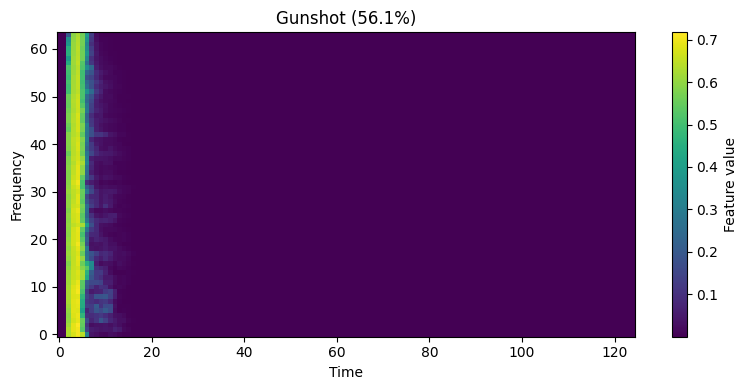

In [60]:
# predict("/kaggle/input/datasets/vaibhavchaudhary37/clapping-testing1/Olpad.m4a", show_plot=True)
# predict_folder("/kaggle/input/datasets/vaibhavchaudhary37/clapping-testing1")
audio_path = "/kaggle/input/datasets/vaibhavchaudhary37/gunshot-testing2/mixkit-game-gun-shot-1662.mp3"

pred, confidence = predict(
    audio_path,
    show_plot=True
)

In [63]:
# import os

# audio_ext = (".wav", ".mp3", ".flac", ".ogg", ".m4a")

# for root, dirs, files in os.walk("/kaggle"):
#     for file in files:
#         if file.lower().endswith(audio_ext):
#             print(os.path.join(root, file))
# ============================================================
# FOLDER PREDICTION
# ============================================================

def predict_folder(folder):

    if not os.path.isdir(folder):
        raise NotADirectoryError(
            f"Folder not found:\n{folder}"
        )

    results = []

    audio_extensions = tuple(
        ext.lower()
        for ext in AUDIO_EXTENSIONS
    )

    files = sorted(
        os.listdir(folder)
    )

    for file in files:

        if not file.lower().endswith(
            audio_extensions
        ):
            continue

        path = os.path.join(
            folder,
            file
        )

        try:

            pred, conf = predict(
                path,
                show_plot=False
            )

            results.append([
                file,
                CLASS_NAMES[pred],
                conf
            ])

        except Exception as e:

            print(
                f"Error processing {file}: {e}"
            )

            results.append([
                file,
                "ERROR",
                np.nan
            ])

    # Create DataFrame
    results_df = pd.DataFrame(
        results,
        columns=[
            "File",
            "Prediction",
            "Confidence"
        ]
    )

    # Confidence as percentage
    results_df["Confidence_Percent"] = (
        results_df["Confidence"] * 100
    )

    # Save
    output_path = (
        "/kaggle/working/"
        "inference_results_corrected.csv"
    )

    results_df.to_csv(
        output_path,
        index=False
    )

    print("\n" + "=" * 60)
    print("FOLDER INFERENCE COMPLETE")
    print("=" * 60)

    print(
        f"Files processed: {len(results_df)}"
    )

    print(
        f"Results saved to:\n{output_path}"
    )

    return results_df

In [65]:
folder_path = "/kaggle/input/datasets/niranjankn/esc50/ESC-50-master/audio"

results_df = predict_folder(
    folder_path
)

display(results_df)

AUDIO PREDICTION
File: 1-100032-A-0.wav
Prediction : Non-Gunshot
Confidence : 98.21%
Non-Gunshot probability : 98.21%
Gunshot probability     : 1.79%
AUDIO PREDICTION
File: 1-100038-A-14.wav
Prediction : Non-Gunshot
Confidence : 99.84%
Non-Gunshot probability : 99.84%
Gunshot probability     : 0.16%
AUDIO PREDICTION
File: 1-100210-A-36.wav
Prediction : Non-Gunshot
Confidence : 99.86%
Non-Gunshot probability : 99.86%
Gunshot probability     : 0.14%
AUDIO PREDICTION
File: 1-100210-B-36.wav
Prediction : Non-Gunshot
Confidence : 99.89%
Non-Gunshot probability : 99.89%
Gunshot probability     : 0.11%
AUDIO PREDICTION
File: 1-101296-A-19.wav
Prediction : Non-Gunshot
Confidence : 99.62%
Non-Gunshot probability : 99.62%
Gunshot probability     : 0.38%
AUDIO PREDICTION
File: 1-101296-B-19.wav
Prediction : Non-Gunshot
Confidence : 99.62%
Non-Gunshot probability : 99.62%
Gunshot probability     : 0.38%
AUDIO PREDICTION
File: 1-101336-A-30.wav
Prediction : Non-Gunshot
Confidence : 95.25%
Non-Gunsh

,File,Prediction,Confidence,Confidence_Percent
0,1-100032-A-0.wav,Non-Gunshot,0.982065,98.206550
1,1-100038-A-14.wav,Non-Gunshot,0.998448,99.844813
2,1-100210-A-36.wav,Non-Gunshot,0.998567,99.856746
3,1-100210-B-36.wav,Non-Gunshot,0.998897,99.889696
4,1-101296-A-19.wav,Non-Gunshot,0.996220,99.621993
...,...,...,...,...
1995,5-263831-B-6.wav,Non-Gunshot,0.993996,99.399638
1996,5-263902-A-36.wav,Non-Gunshot,0.999460,99.946004
1997,5-51149-A-25.wav,Non-Gunshot,0.983971,98.397082
1998,5-61635-A-8.wav,Non-Gunshot,0.999449,99.944931
